# First-Order Linear ODEs and Euler Methods

**References:** `Notes/lec9.pdf` (Lecture 9), `Notes/problem_set_III.pdf` (Q1), `n/Nuclear-decay.ipynb`, `Notes/Quiz2/08_ODE_Systems_and_Nonlinear_Solvers.ipynb`

## Concept & Formulas
Model equation (Radioactive Decay): $\frac{dN}{dt} = -\lambda N$ with exact solution $N(t) = N_0 e^{-\lambda t}$.

- **Simple (Forward) Euler:** $N_{n+1} = N_n(1 - \lambda \Delta t)$ — first-order accurate, error $O(\Delta t)$.
- **Improved Euler (Midpoint / Heun):** $N_{n+1} = N_n\left(1 - \lambda\Delta t + \frac{(\lambda\Delta t)^2}{2}\right)$ — second-order accurate, error $O(\Delta t^2)$.
- **Implicit (Backward) Euler:** $N_{n+1} = N_n - \lambda\Delta t\, N_{n+1} \implies N_{n+1} = \frac{N_n}{1 + \lambda \Delta t}$.
- **Stability Condition (Forward Euler):** Requires $|1 - \lambda\Delta t| < 1$, i.e., $\Delta t < \frac{2}{\lambda}$ (and $\Delta t < \frac{1}{\lambda}$ to avoid sign oscillations). Implicit Euler is stable for **any** $\Delta t > 0$.
- **Limitations:** Forward Euler blows up if $\Delta t$ is too large and accumulates drift over long times.

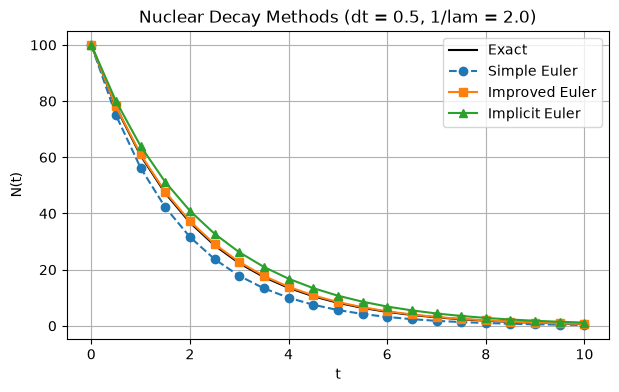

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Compare Simple Euler, Improved Euler, and Implicit Euler (stable step size)
lam = 0.5
N0 = 100.0
dt = 0.5      # 1/lam = 2.0, so dt = 0.5 is well inside stability limit
t = np.arange(0, 10 + dt, dt)
n = len(t)

N_exact = N0 * np.exp(-lam * t)
N_euler = np.zeros(n)
N_imp = np.zeros(n)
N_implicit = np.zeros(n)

N_euler[0] = N0
N_imp[0] = N0
N_implicit[0] = N0

for i in range(n - 1):
    N_euler[i + 1] = N_euler[i] * (1 - lam * dt)
    N_imp[i + 1] = N_imp[i] * (1 - lam * dt + 0.5 * (lam * dt)**2)
    N_implicit[i + 1] = N_implicit[i] / (1 + lam * dt)

plt.figure(figsize=(7, 4))
plt.plot(t, N_exact, 'k-', label='Exact')
plt.plot(t, N_euler, 'o--', label='Simple Euler')
plt.plot(t, N_imp, 's-', label='Improved Euler')
plt.plot(t, N_implicit, '^-', label='Implicit Euler')
plt.xlabel('t')
plt.ylabel('N(t)')
plt.title(f'Nuclear Decay Methods (dt = {dt}, 1/lam = {1/lam})')
plt.legend()
plt.grid(True)
plt.show()

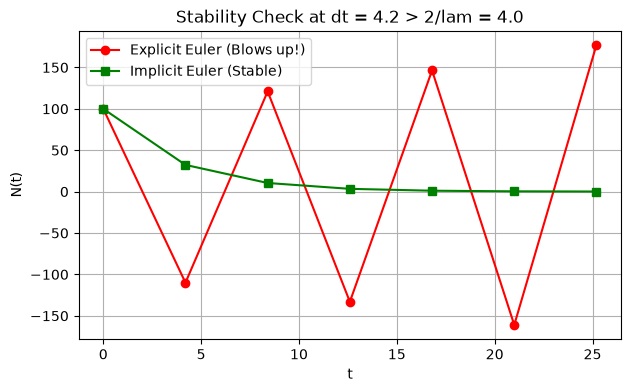

In [2]:
# Instability demonstration when dt > 2 / lam (here 2 / lam = 4.0)
dt_big = 4.2
t_big = np.arange(0, 25 + dt_big, dt_big)
n_big = len(t_big)

N_exp_big = np.zeros(n_big)
N_imp_big = np.zeros(n_big)
N_exp_big[0] = N0
N_imp_big[0] = N0

for i in range(n_big - 1):
    N_exp_big[i + 1] = N_exp_big[i] * (1 - lam * dt_big)
    N_imp_big[i + 1] = N_imp_big[i] / (1 + lam * dt_big)

plt.figure(figsize=(7, 4))
plt.plot(t_big, N_exp_big, 'r-o', label='Explicit Euler (Blows up!)')
plt.plot(t_big, N_imp_big, 'g-s', label='Implicit Euler (Stable)')
plt.xlabel('t')
plt.ylabel('N(t)')
plt.title(f'Stability Check at dt = {dt_big} > 2/lam = 4.0')
plt.legend()
plt.grid(True)
plt.show()

---
## Class Notebook Code (`n/Nuclear-decay.ipynb`)
Exact functions written in class for analytical decay, Simple Euler, and Improved Euler.

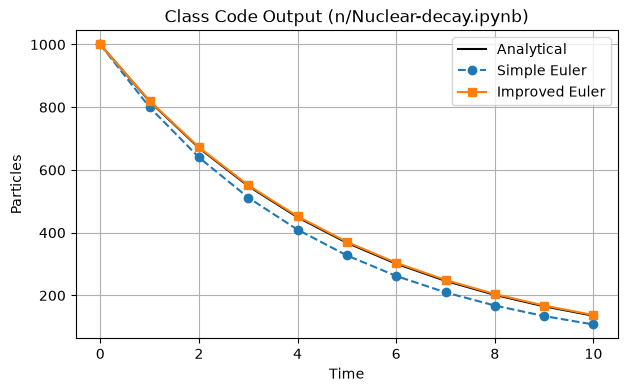

In [3]:
# Exact functions from n/Nuclear-decay.ipynb
def decay(init_particles, lamb, time):
    return init_particles * np.exp(-lamb * time)

def simple_euler(N0, lamb, dt, n):
    N = np.zeros(n)
    N[0] = N0
    for i in range(n - 1):
        N[i + 1] = N[i] * (1 - lamb * dt)
    return N

def improved_euler(N0, lamb, dt, n):
    N = np.zeros(n)
    N[0] = N0
    for i in range(n - 1):
        N[i + 1] = N[i] * (1 - lamb * dt * (1 - lamb * dt * 0.5))
    return N

dt_c = 1.0
t_c = np.arange(0, 10 + dt_c, dt_c)
plt.figure(figsize=(7, 4))
plt.plot(t_c, decay(1000, 0.2, t_c), 'k-', label='Analytical')
plt.plot(t_c, simple_euler(1000, 0.2, dt_c, len(t_c)), 'o--', label='Simple Euler')
plt.plot(t_c, improved_euler(1000, 0.2, dt_c, len(t_c)), 's-', label='Improved Euler')
plt.xlabel('Time')
plt.ylabel('Particles')
plt.title('Class Code Output (n/Nuclear-decay.ipynb)')
plt.legend()
plt.grid(True)
plt.show()